### Downloadin and preparing the video

Note: you may need to restart the kernel to use updated packages.
Hit:1 http://deb.debian.org/debian bookworm InRelease
Hit:2 http://deb.debian.org/debian bookworm-updates InRelease
Hit:3 http://deb.debian.org/debian-security bookworm-security InRelease
Hit:4 https://dl.yarnpkg.com/debian stable InRelease
Reading package lists... Done
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ffmpeg is already the newest version (7:5.1.6-0+deb12u1).
libsm6 is already the newest version (2:1.2.3-1).
libxext6 is already the newest version (2:1.3.4-1+b1).
libgl1 is already the newest version (1.6.0-1).
0 upgraded, 0 newly installed, 0 to remove and 50 not upgraded.


/workspaces/eng-ai-agents/.venv/lib/python3.11/site-packages/torchvision/io/video.py:169: UserWarning: The pts_unit 'pts' gives wrong results. Please use pts_unit 'sec'.
  warnings.warn("The pts_unit 'pts' gives wrong results. Please use pts_unit 'sec'.")


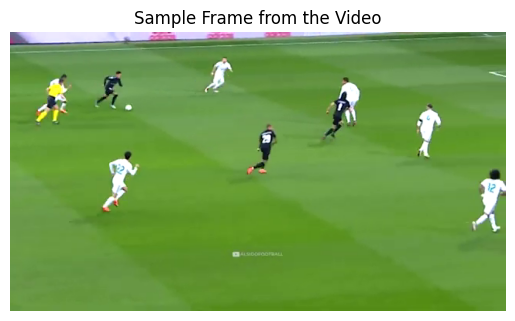

In [1]:
%pip install pytubefix pyav
!sudo apt-get update && sudo apt-get install ffmpeg libsm6 libxext6 libgl1  -y

from pytubefix import YouTube
import os
from torchvision.io import read_video, write_png
import matplotlib.pyplot as plt
import torch

yt = YouTube('https://www.youtube.com/watch?v=l3NJNFmg09k')
out = yt.streams.filter(progressive=True, file_extension='mp4').order_by('resolution').desc().first().download()
video_path = 'input.mp4'
os.rename(out, video_path)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
video, audio, meta = read_video(video_path)
frames = video.permute(0, 3, 1, 2)

frame = frames[500]

plt.imshow(frame.permute(1, 2, 0))
plt.title("Sample Frame from the Video")
plt.axis("off")
plt.show()

write_png(frame, "sample.png")

### Model Overview
Firstly we gonna take a look at the FasterRCNN model layers implemented in pytorch before we take a closer look at the RPN and ROI Layers specifically.

![](./faster-rcnn.png)

#### 1. Transform:
This applies preprocessing transformations to the input images.

#### 2. Backbone with FPN (Feature Pyramid Network):

- Body: A ResNet50 for extracting features from the input images. It includes convolutional and batch normalization layers, interspersed with ReLU activations. This structure progressively extracts higher-level features at different spatial scales.
- FPN: The Feature Pyramid Network builds a feature hierarchy to detect objects at multiple scales, with inner and layer blocks that refine and enrich features at various resolutions.

#### 3. Region Proposal Network (RPN):

- Anchor Generator: Generates anchor boxes (predefined bounding boxes) across the image at multiple scales and aspect ratios.
- RPN Head: A small network that classifies anchors as background or foreground and adjusts their positions for more accurate proposals.

#### 4. RoI Heads:

- RoI Pooling (MultiScaleRoIAlign): Extracts features of each region of interest (RoI) proposed by the RPN and resizes them to a fixed size (7x7).
- Box Head: A fully connected head for further processing the RoI features. It consists of several convolutional and fully connected layers, ending in a classification and a bounding box regression head.
- Box Predictor: Outputs the final class scores and bounding box adjustments.

This Faster R-CNN model uses a deep convolutional backbone with a feature pyramid, enabling it to handle object detection across scales efficiently. The RPN suggests candidate regions, and the RoI head processes these regions to classify and refine their bounding boxes



In [2]:
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights

print(f"Using {device}")

weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
preprocess = weights.transforms()
model = fasterrcnn_resnet50_fpn_v2(weights=weights, box_score_thresh=0.9 )
model = model.to(device)
model.eval()

### Registering Hooks to visualize each layer
activation = {}
def getActivation(name):
    def hook(model, input, output):
        activation[name] = output
    return hook

for name, child  in model.named_children():
    print(f"{name} :  {child}")
    handle = child.register_forward_hook(getActivation(name))

#### Sample prediction for one Frame to show activation
sample_frame = preprocess(frame).to(device)


with torch.no_grad():
    prediction = model([sample_frame])[0]
    print(prediction)

Using cuda
transform :  GeneralizedRCNNTransform(
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    Resize(min_size=(800,), max_size=1333, mode='bilinear')
)
backbone :  BackboneWithFPN(
  (body): IntermediateLayerGetter(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_

#### Transform Layer
The Transform Layer preprocesses the input image by normalizing it and resizing it to fit the model's expected input dimensions. Normalization ensures consistent pixel intensity ranges across images, while resizing adapts the input dimensions to the model's architecture.

In PyTorch’s Faster R-CNN implementation, the following parameters are used for preprocessing:

- min_size=800: Minimum size of the smaller image dimension.
- max_size=1333: Maximum size of the larger image dimension.
- image_mean = [0.485, 0.456, 0.406]: Mean values for normalization.
- image_std = [0.229, 0.224, 0.225]: Standard deviation values for normalization.

The transformation is applied using the following code:
```python
forward(self, images, targets=None)
...

images, targets = self.transform(images, targets)
...

```

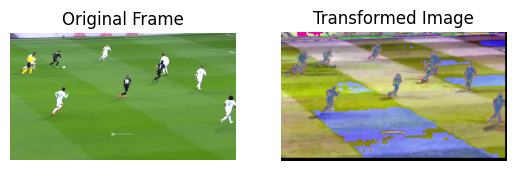

In [16]:
from torchvision.transforms.functional import to_pil_image

transformed_images, _ = activation["transform"]

transformed_image = transformed_images.tensors[0]

transformed_pil_image = to_pil_image(transformed_image)

plt.subplot(1, 2, 1)
plt.imshow(frame.permute(1, 2, 0))
plt.title("Original Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(transformed_pil_image)
plt.title("Transformed Image")
plt.axis("off")

plt.show()

#### Backbone Layer
The Backbone Layer, in this case a pretrained ResNet50 with FPN, processes the transformed image to extract hierarchical feature maps. ResNet50 serves as a deep convolutional network for feature extraction, while the Feature Pyramid Network (FPN) enriches features at different scales, enabling robust object detection across various object sizes.

The backbone outputs feature maps at different levels of the FPN. These feature maps are used by subsequent layers, such as the Region Proposal Network (RPN) and RoI Heads, for object detection and bounding box refinement.

```python
forward(self, images, targets=None)
    ...
    features = self.backbone(images.tensors)
    if isinstance(features, torch.Tensor):
        features = OrderedDict([("0", features)])
    ...
```

Feature map '0' shape: torch.Size([1, 256, 192, 336])
Feature map '1' shape: torch.Size([1, 256, 96, 168])
Feature map '2' shape: torch.Size([1, 256, 48, 84])
Feature map '3' shape: torch.Size([1, 256, 24, 42])
Feature map 'pool' shape: torch.Size([1, 256, 12, 21])


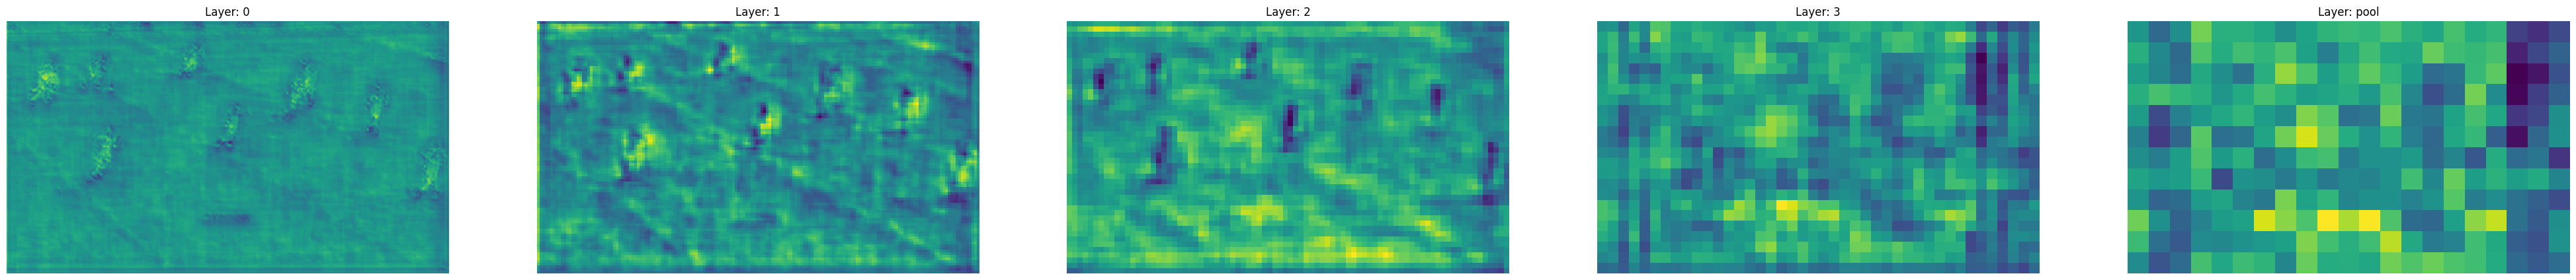

In [17]:
import matplotlib.pyplot as plt
backbone_features = activation['backbone']

fig = plt.figure(figsize=(50, 50))

for i, (k, v) in enumerate(backbone_features.items()):
    print(f"Feature map '{k}' shape: {v.shape}")
    feature_map = backbone_features[k][0]
    feature_map_mean = feature_map.mean(dim=0)

    feature_map_norm = (feature_map_mean - feature_map_mean.min()) / (feature_map_mean.max() - feature_map_mean.min())

    a = fig.add_subplot(1, 5, i+1)
    imgplot = plt.imshow(feature_map_norm.cpu().detach())
    a.set_title(f"Layer: {k}")
    a.axis("off")

plt.show()

#### Region Proposal Network (RPN)
The RPN takes in the Feature map from the previus layer.

At each feature map region, the RPN places anchor boxes of various scales and aspect ratios in this case 9 per cell with varying shapes and sizes. Anchor boxes are predefined bounding boxes of varying sizes and aspect ratios designed to detect objects at different scales and shapes.

Furthemore anchor box generation is implement as follows:

```python
def _default_anchorgen():
    anchor_sizes = ((32,), (64,), (128,), (256,), (512,))
    aspect_ratios = ((0.5, 1.0, 2.0),) * len(anchor_sizes)
    return AnchorGenerator(anchor_sizes, aspect_ratios)
```

- Anchor Sizes:
  - Defined as ((32,), (64,), (128,), (256,), (512,)), these sizes are general-purpose defaults in PyTorch's Faster R-CNN implementation. They are designed to detect objects of various scales, ranging from small objects (32 pixels) to large objects (512 pixels) across the input image.
- Aspect Ratios:
  - 0.5: Wide (e.g., 2:1).
  - 1.0: Square.
  - 2.0: Tall (e.g., 1:2).

This dense grid of anchor boxes ensures that objects of varying sizes and shapes are captured across the spatial extent of the feature map.


##### Binary Classification and Bounding Box Regression:

For each anchor box, the RPN performs two tasks:
- Binary classification: It predicts whether each anchor is likely to contain an object (foreground) or is background.
- Bounding box regression: For anchors classified as foreground, the RPN also predicts adjustments to refine the anchor box coordinates, making them better fit the object it encloses.

Output:

The RPN then filters out the anchor boxes based on their scores (confidence in being foreground) and applies non-maximum suppression (NMS) to remove redundant boxes. The result is a set of region proposals that are likely to contain objects. These region proposals are passed to the RoI Heads for further classification and refinement.

The key idea here is that the RPN essentially learns to suggest potential object locations with a high probability and good positioning, reducing the number of regions Faster R-CNN needs to inspect in detail.

```python
forward(self, images, targets=None)
    ...
    proposals, proposal_losses = self.rpn(images, features, targets)
    ...
```

(-0.5, 639.5, 359.5, -0.5)

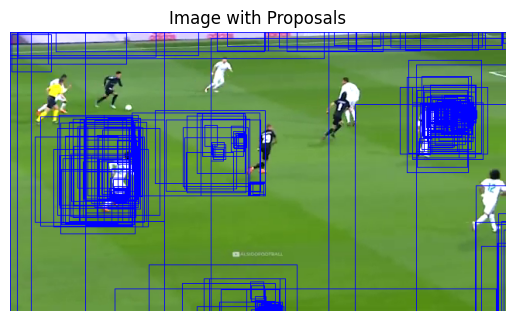

In [33]:
from torchvision.ops import nms
from torchvision.utils import draw_bounding_boxes

rpn_outputs = activation['rpn']

proposals = rpn_outputs[0]

proposals_per_image = proposals[0].clone().to(device)


scores = torch.ones(proposals_per_image.size(0), device=device)
keep = nms(proposals_per_image, scores, iou_threshold=0.7)
proposals_per_image = proposals_per_image[keep]


num_proposals_to_draw = 500
proposals_to_draw = proposals_per_image[:num_proposals_to_draw]

img_uint8 = (sample_frame * 255).type(torch.uint8)
img_with_proposals = draw_bounding_boxes(img_uint8, boxes=proposals_to_draw, colors="blue", width=1)

img_with_proposals_pil = to_pil_image(img_with_proposals)
plt.imshow(img_with_proposals_pil)
plt.title("Image with Proposals")
plt.axis("off")


For visualization purposes only a fraction of the proposals are shown in the output above. You can already observe that alot of predictions are clusterd arround the players.

#### ROI Pooling Layer
The RoI (Regions of Interest) Pooling layer takes in the RoI e.g bounding box proposal of diffrent size from the RPN. It then divides each RoI into a 7x7 bins and applys Max Pooling on each bin to obtain a fixed-size feature map of shape 7x7xC for each RoI. The depth (number of channels) remains the same as the input feature map. This Step converts variable-sized RoIs into fixed-size feature maps, allowing them to be processed uniformly in the subsequent layers.

##### Prediction Heads
After RoI pooling, each fixed-size feature map (e.g., 7x7xC) is flattened into a 1D vector. This is necessary to feed the features into fully connected (FC) layers.

Two Separate Heads process these vectors:
- Classification Head: 
  - Predicts the class probabilities for each RoI. It essentially outputs a probability distribution over all possible object classes plus a "background" class.
- Bounding Box Regression Head: 
  - Predicts bounding box adjustments. It outputs refined coordinates (e.g., adjustments to the x, y, width, and height) for the RoI, fine-tuning the bounding box location and dimensions to better fit the detected object.

Final Output: After these heads, you get the final detections:

- A class label (or background) for each RoI.
- Refined bounding box coordinates for each detected object.

```python
forward(self, images, targets=None)
    ...
    detections, detector_losses = self.roi_heads(features, proposals, images.image_sizes, targets)
    detections = self.transform.postprocess(detections, images.image_sizes, original_image_sizes)
    ...
    return detections
```

(-0.5, 639.5, 359.5, -0.5)

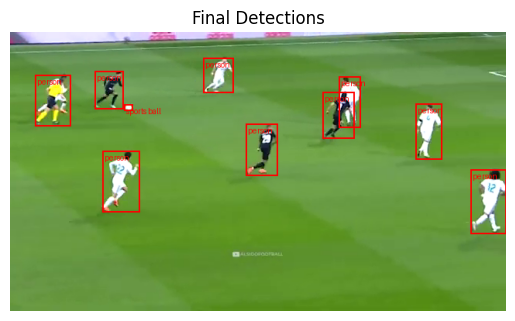

In [6]:
roi_heads_outputs = activation['roi_heads']

detections = roi_heads_outputs[0]

detection = detections[0]

scores = detection['scores']
keep_idxs = scores > 0.9
boxes = detection['boxes'][keep_idxs]
labels = detection['labels'][keep_idxs]

category_names = [weights.meta["categories"][i] for i in labels]

img_with_detections = draw_bounding_boxes(img_uint8, boxes=boxes, labels=category_names, colors="red", width=2)
img_with_detections_pil = to_pil_image(img_with_detections)
plt.imshow(img_with_detections_pil)
plt.title("Final Detections")
plt.axis("off")


### Run detection on each Frame

Since we have seen and understand how Faster RCNN works on a single Frame we are now able to process the whole video.

In [7]:
from tqdm import tqdm

output_frames = []

for frame in tqdm(frames, desc="Processing Frames"):
    input_frame = preprocess(frame).to(device)

    with torch.no_grad():
        prediction = model([input_frame])[0]

    labels = [weights.meta["categories"][i] for i in prediction["labels"]]
    box = draw_bounding_boxes(frame,
                            boxes=prediction["boxes"],
                            labels=labels,
                            colors="blue",
                            width=2)

    output_frames.append(box.to(torch.uint8))

Processing Frames: 100%|██████████| 1074/1074 [09:56<00:00,  1.80it/s]


#### Create the output video

Finaly combine each processed Frame to a new video.

In [8]:

from torchvision.io import write_video

output_video = torch.stack(output_frames).permute(0, 2, 3, 1)  # Shape (T, H, W, C)
write_video(
    "output.mp4",
    video_array=output_video,
    audio_array=audio,
    audio_codec='aac',
    audio_fps=int(meta['audio_fps']),
    fps=int(meta['video_fps']),
    video_codec='h264',
    options={'crf': '18'}
)

#### Reduced Pytorch Source implementation for refrence
```python
def fasterrcnn_resnet50_fpn_v2(
    *,
    weights: Optional[FasterRCNN_ResNet50_FPN_V2_Weights] = None,
    progress: bool = True,
    num_classes: Optional[int] = None,
    weights_backbone: Optional[ResNet50_Weights] = None,
    trainable_backbone_layers: Optional[int] = None,
    **kwargs: Any,
) -> FasterRCNN:
    weights = FasterRCNN_ResNet50_FPN_V2_Weights.verify(weights)
    weights_backbone = ResNet50_Weights.verify(weights_backbone)

    if weights is not None:
        weights_backbone = None
        num_classes = _ovewrite_value_param("num_classes", num_classes, len(weights.meta["categories"]))
    elif num_classes is None:
        num_classes = 91

    is_trained = weights is not None or weights_backbone is not None
    trainable_backbone_layers = _validate_trainable_layers(is_trained, trainable_backbone_layers, 5, 3)

    backbone = resnet50(weights=weights_backbone, progress=progress)
    backbone = _resnet_fpn_extractor(backbone, trainable_backbone_layers, norm_layer=nn.BatchNorm2d)
    rpn_anchor_generator = _default_anchorgen()
    rpn_head = RPNHead(backbone.out_channels, rpn_anchor_generator.num_anchors_per_location()[0], conv_depth=2)
    box_head = FastRCNNConvFCHead(
        (backbone.out_channels, 7, 7), [256, 256, 256, 256], [1024], norm_layer=nn.BatchNorm2d
    )
    model = FasterRCNN(
        backbone,
        num_classes=num_classes,
        rpn_anchor_generator=rpn_anchor_generator,
        rpn_head=rpn_head,
        box_head=box_head,
        **kwargs,
    )

    if weights is not None:
        model.load_state_dict(weights.get_state_dict(progress=progress, check_hash=True))

    return model

class FasterRCNN(GeneralizedRCNN):
    def __init__(
        self,
        backbone,
        num_classes=None,
        # transform parameters
        min_size=800,
        max_size=1333,
        image_mean=None,
        image_std=None,
        # RPN parameters
        rpn_anchor_generator=None,
        rpn_head=None,
        rpn_pre_nms_top_n_train=2000,
        rpn_pre_nms_top_n_test=1000,
        rpn_post_nms_top_n_train=2000,
        rpn_post_nms_top_n_test=1000,
        rpn_nms_thresh=0.7,
        rpn_fg_iou_thresh=0.7,
        rpn_bg_iou_thresh=0.3,
        rpn_batch_size_per_image=256,
        rpn_positive_fraction=0.5,
        rpn_score_thresh=0.0,
        # Box parameters
        box_roi_pool=None,
        box_head=None,
        box_predictor=None,
        box_score_thresh=0.05,
        box_nms_thresh=0.5,
        box_detections_per_img=100,
        box_fg_iou_thresh=0.5,
        box_bg_iou_thresh=0.5,
        box_batch_size_per_image=512,
        box_positive_fraction=0.25,
        bbox_reg_weights=None,
        **kwargs,
    ):
        out_channels = backbone.out_channels

        if rpn_anchor_generator is None:
            rpn_anchor_generator = _default_anchorgen()
        if rpn_head is None:
            rpn_head = RPNHead(out_channels, rpn_anchor_generator.num_anchors_per_location()[0])

        rpn_pre_nms_top_n = dict(training=rpn_pre_nms_top_n_train, testing=rpn_pre_nms_top_n_test)
        rpn_post_nms_top_n = dict(training=rpn_post_nms_top_n_train, testing=rpn_post_nms_top_n_test)

        rpn = RegionProposalNetwork(
            rpn_anchor_generator,
            rpn_head,
            rpn_fg_iou_thresh,
            rpn_bg_iou_thresh,
            rpn_batch_size_per_image,
            rpn_positive_fraction,
            rpn_pre_nms_top_n,
            rpn_post_nms_top_n,
            rpn_nms_thresh,
            score_thresh=rpn_score_thresh,
        )

        if box_roi_pool is None:
            box_roi_pool = MultiScaleRoIAlign(featmap_names=["0", "1", "2", "3"], output_size=7, sampling_ratio=2)

        if box_head is None:
            resolution = box_roi_pool.output_size[0]
            representation_size = 1024
            box_head = TwoMLPHead(out_channels * resolution**2, representation_size)

        if box_predictor is None:
            representation_size = 1024
            box_predictor = FastRCNNPredictor(representation_size, num_classes)

        roi_heads = RoIHeads(
            # Box
            box_roi_pool,
            box_head,
            box_predictor,
            box_fg_iou_thresh,
            box_bg_iou_thresh,
            box_batch_size_per_image,
            box_positive_fraction,
            bbox_reg_weights,
            box_score_thresh,
            box_nms_thresh,
            box_detections_per_img,
        )

        if image_mean is None:
            image_mean = [0.485, 0.456, 0.406]
        if image_std is None:
            image_std = [0.229, 0.224, 0.225]
        transform = GeneralizedRCNNTransform(min_size, max_size, image_mean, image_std, **kwargs)

        super().__init__(backbone, rpn, roi_heads, transform)

class GeneralizedRCNN(nn.Module):
    def __init__(self, backbone: nn.Module, rpn: nn.Module, roi_heads: nn.Module, transform: nn.Module) -> None:
        super().__init__()
        _log_api_usage_once(self)
        self.transform = transform
        self.backbone = backbone
        self.rpn = rpn
        self.roi_heads = roi_heads
        # used only on torchscript mode
        self._has_warned = False

    def forward(self, images, targets=None):
        if self.training:
            if targets is None:
                torch._assert(False, "targets should not be none when in training mode")
            else:
                for target in targets:
                    boxes = target["boxes"]


        original_image_sizes: List[Tuple[int, int]] = []
        for img in images:
            val = img.shape[-2:]
            original_image_sizes.append((val[0], val[1]))

        images, targets = self.transform(images, targets)


        if targets is not None:
            for target_idx, target in enumerate(targets):
                boxes = target["boxes"]
                degenerate_boxes = boxes[:, 2:] <= boxes[:, :2]
                if degenerate_boxes.any():
                    bb_idx = torch.where(degenerate_boxes.any(dim=1))[0][0]
                    degen_bb: List[float] = boxes[bb_idx].tolist()


        features = self.backbone(images.tensors)
        if isinstance(features, torch.Tensor):
            features = OrderedDict([("0", features)])
        proposals, proposal_losses = self.rpn(images, features, targets)
        detections, detector_losses = self.roi_heads(features, proposals, images.image_sizes, targets)
        detections = self.transform.postprocess(detections, images.image_sizes, original_image_sizes)

        losses = {}
        losses.update(detector_losses)
        losses.update(proposal_losses)

        if self.training:
            return losses

        return detections
```